<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>


#### Import the required libraries we need for the lab.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL


In [2]:
boston_df=pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv')

#### Add your code below following the instructions given in the course to complete the peer graded assignment


### 1.1 Display the First 5 Rows of the Dataset

In [3]:
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


### 1.2 Display the Data Types of Each Column

In [4]:
boston_df.dtypes

Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           float64
TAX           float64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object

### 1.3 Check for Missing Values in Each Column

In [5]:
boston_df.isnull().sum()

Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
LSTAT         0
MEDV          0
dtype: int64

### 1.4 Check for Duplicate Rows

In [6]:
boston_df.duplicated().sum()

np.int64(0)

### 1.5 Display the Correlation Matrix

In [7]:
boston_df.corr()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
Unnamed: 0,1.000000,0.407407,-0.103393,0.399439,-0.003759,0.398736,-0.079971,0.203784,-0.302211,0.686002,0.666626,0.291074,0.258465,-0.226604
CRIM,0.407407,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305
ZN,-0.103393,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445
INDUS,0.399439,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725
CHAS,-0.003759,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260
NOX,0.398736,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321
RM,-0.079971,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360
AGE,0.203784,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955
DIS,-0.302211,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929
RAD,0.686002,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626


### 2.1 Display Descriptive Statistics of the Dataset

In [8]:
boston_df.describe()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


### 2.2 Create a Boxplot for MEDV (Median Value of Owner-Occupied Homes)

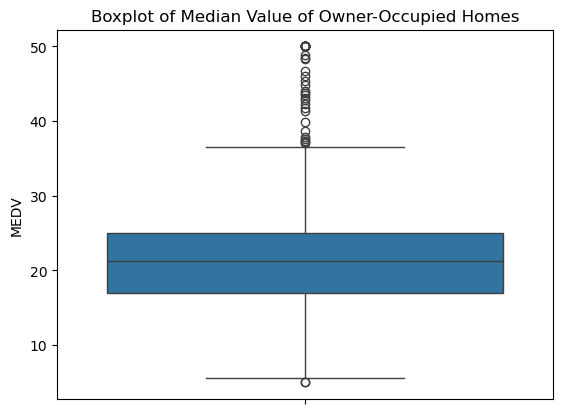

In [9]:
sns.boxplot(y='MEDV', data=boston_df)
pyplot.title('Boxplot of Median Value of Owner-Occupied Homes')
pyplot.ylabel('MEDV')
pyplot.show()

The median MEDV is about 21.2, with most values between roughly 17 and 25 (the interquartile range). Several outliers sit at the high end, and many values stop at exactly 50, which suggests the data is capped at that level.

### 2.3 Create a Bar Plot for CHAS (Charles River Dummy Variable)

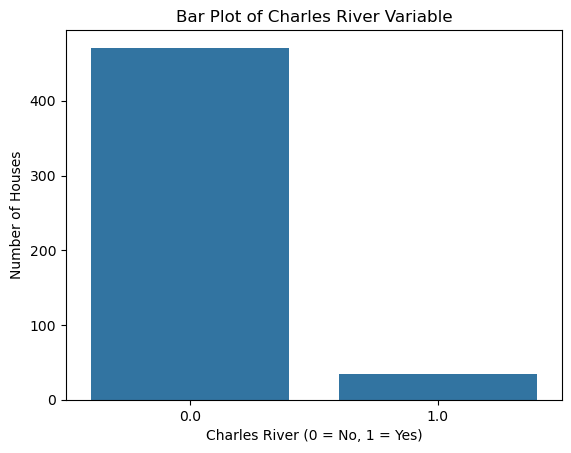

In [10]:
sns.countplot(x='CHAS', data=boston_df)
pyplot.title('Bar Plot of Charles River Variable')
pyplot.xlabel('Charles River (0 = No, 1 = Yes)')
pyplot.ylabel('Number of Houses')
pyplot.show()

The bar plot shows the number of properties located near the Charles River compared with those that are not. The majority of properties are not bounded by the Charles River, while a much smaller number are located near it. This indicates that the dataset contains an unequal number of observations in the two groups.

### 2.4 Discretize AGE into Three Groups and Create a Boxplot of MEDV

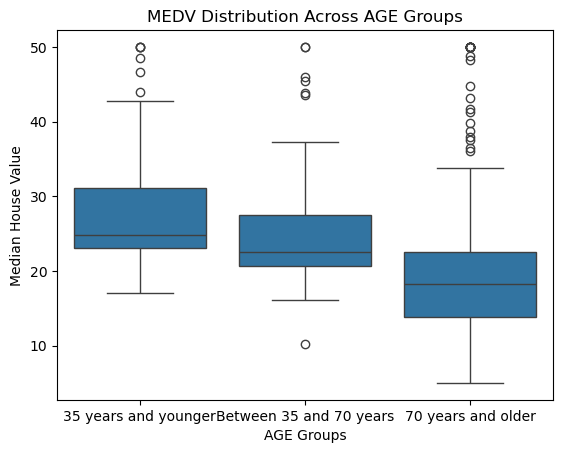

In [11]:
boston_df['AGE_Group'] = pd.cut(
    boston_df['AGE'],
    bins=[0, 35, 70, 100],
    labels=['35 years and younger', 'Between 35 and 70 years', '70 years and older']
)

sns.boxplot(x='AGE_Group', y='MEDV', data=boston_df)
pyplot.title('MEDV Distribution Across AGE Groups')
pyplot.xlabel('AGE Groups')
pyplot.ylabel('Median House Value')
pyplot.show()

The boxplot compares median house values across three groups based on the proportion of owner-occupied units built before 1940. Median values fall as the proportion of older housing rises, with the 70+ group showing the lowest values. This suggests older housing stock is associated with lower prices; the ANOVA in Task 3 tests this formally.

### 2.5 Create a Scatter Plot Showing the Relationship Between NOX and INDUS

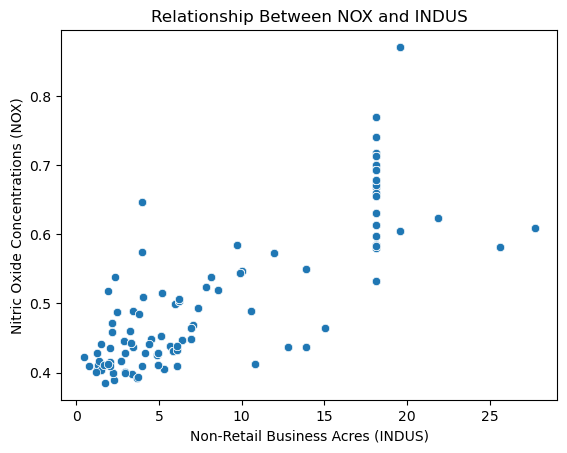

In [12]:
sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
pyplot.title('Relationship Between NOX and INDUS')
pyplot.xlabel('Non-Retail Business Acres (INDUS)')
pyplot.ylabel('Nitric Oxide Concentrations (NOX)')
pyplot.show()

The scatter plot shows a positive relationship: towns with a larger proportion of non-retail business acres generally have higher nitric oxide concentrations. The points rise together, and the Pearson test in Task 3 quantifies the strength of this relationship.

### 2.6 Create a Histogram for PTRATIO (Pupil-Teacher Ratio)

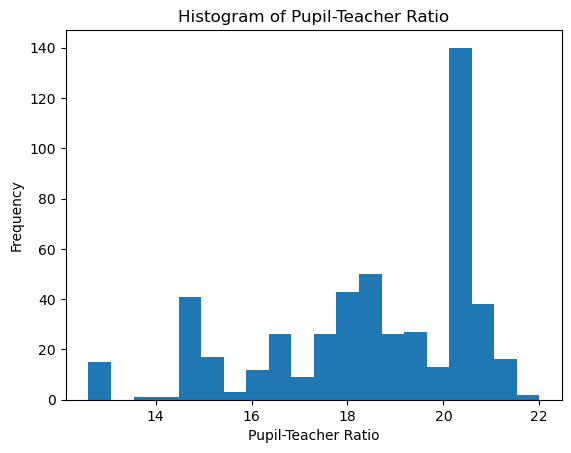

In [13]:
pyplot.hist(boston_df['PTRATIO'], bins=20)
pyplot.title('Histogram of Pupil-Teacher Ratio')
pyplot.xlabel('Pupil-Teacher Ratio')
pyplot.ylabel('Frequency')
pyplot.show()

The histogram displays the distribution of pupil-teacher ratios across the Boston housing areas. Most observations are concentrated around the middle range, while fewer areas have particularly low or high ratios. This helps us understand how pupil-teacher ratios vary across the different areas included in the dataset.

### 3.1 Use Levene's Test to Check Equality of Variances

In [14]:
scipy.stats.levene(
    boston_df[boston_df['CHAS'] == 0]['MEDV'],
    boston_df[boston_df['CHAS'] == 1]['MEDV']
)

LeveneResult(statistic=np.float64(4.590342218715871), pvalue=np.float64(0.03263097600633006))

**Hypotheses**
- H₀: The variance of MEDV is equal for homes bounded by the Charles River (CHAS = 1) and homes not bounded by it (CHAS = 0).
- H₁: The variances are not equal.
- Significance level: α = 0.05

**Result:** Levene statistic = 4.59, p-value = 0.0326

**Conclusion:** Since p = 0.0326 < 0.05, we reject H₀. The variances of MEDV differ between the two groups, so the equal-variance assumption is not met. For the next test we use Welch's t-test (`equal_var=False`).

### 3.2 Perform an Independent Samples T-Test on MEDV

In [15]:
scipy.stats.ttest_ind(
    boston_df[boston_df['CHAS'] == 0]['MEDV'],
    boston_df[boston_df['CHAS'] == 1]['MEDV'],
    equal_var=False
)

TtestResult(statistic=np.float64(-3.113291312794837), pvalue=np.float64(0.0035671700981375174), df=np.float64(36.876408797611994))

**Hypotheses**
- H₀: The mean MEDV is the same for homes bounded and not bounded by the Charles River.
- H₁: The mean MEDV differs between the two groups.
- Significance level: α = 0.05

**Result:** Welch's t-statistic = -3.11, p-value = 0.0036

**Conclusion:** Since p = 0.0036 < 0.05, we reject H₀. There is a statistically significant difference in median home value between the two groups. The negative t-statistic (CHAS = 0 minus CHAS = 1) shows that homes bounded by the Charles River have higher median values. For management, river-adjacent properties command a premium.

### 3.3 Conduct an ANOVA Test to Compare MEDV Across AGE Groups

In [16]:
model = ols('MEDV ~ AGE_Group', data=boston_df).fit()

sm.stats.anova_lm(model, typ=2)

,sum_sq,df,F,PR(>F)
AGE_Group,5401.731883,2.0,36.40765,1.710501e-15
Residual,37314.563532,503.0,NaN,NaN


**Hypotheses**
- H₀: The mean MEDV is equal across the three AGE groups (≤35 years, 35–70 years, ≥70 years).
- H₁: At least one group has a different mean MEDV.
- Significance level: α = 0.05

**Result:** F-statistic = 36.41, p-value ≈ 1.7 × 10⁻¹⁵

**Conclusion:** Since p < 0.05, we reject H₀. Median home values differ significantly across the age groups, and the boxplot suggests that areas with older housing stock (70+ years) have the lowest values. ANOVA tells us that a difference exists but not which groups differ; a post-hoc test such as Tukey's HSD would identify the specific pairs.

### 3.4 Perform a Pearson Correlation Test Between NOX and INDUS

In [17]:
scipy.stats.pearsonr(
    boston_df['NOX'],
    boston_df['INDUS']
)

PearsonRResult(statistic=np.float64(0.763651446920915), pvalue=np.float64(7.913361061241167e-98))

**Hypotheses**
- H₀: There is no linear correlation between NOX and INDUS (ρ = 0).
- H₁: There is a linear correlation between NOX and INDUS (ρ ≠ 0).
- Significance level: α = 0.05

**Result:** Pearson r = 0.764, p-value ≈ 7.9 × 10⁻⁹⁸

**Conclusion:** Since p < 0.05, we reject H₀. There is a strong, statistically significant positive relationship: towns with a larger proportion of non-retail business acres tend to have higher nitric oxide concentrations. About 58% of the variation in NOX is shared with INDUS (r² ≈ 0.58). This is a correlation and does not prove that industrial land causes pollution.

### 3.5 Fit a Simple Linear Regression Model to Evaluate the Impact of DIS on MEDV

In [18]:
model = ols('MEDV ~ DIS', data=boston_df).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        14:40:38   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     18.3901      0.817     22.499      0.0

**Model:** MEDV = β₀ + β₁ × DIS

**Hypotheses**
- H₀: β₁ = 0 (DIS has no effect on MEDV).
- H₁: β₁ ≠ 0.
- Significance level: α = 0.05

**Results**
- Intercept = 18.39
- DIS coefficient = 1.092 (95% CI: 0.722 to 1.462), p < 0.001
- R² = 0.062

**Interpretation:** Each additional unit of weighted distance to the five Boston employment centres is associated with an increase of about 1.09 in MEDV, or roughly $1,092, since MEDV is measured in $1000s. This effect is statistically significant (p < 0.001), so we reject H₀.

However, R² = 0.062 means DIS explains only about 6% of the variation in median home values. Distance matters, but it is a weak predictor on its own, and other variables (such as RM and LSTAT) likely explain far more. The residual diagnostics also show right skew (Skew = 1.47), so the model should be read as indicative rather than precise.

## Conclusions for Management

1. **Charles River:** Homes bounded by the river have significantly higher median values than those that are not (Welch's t-test, p = 0.0036).
2. **Age of housing:** Median home values differ significantly across the three AGE groups (ANOVA, p < 0.001). Areas with a high proportion of pre-1940 homes tend to have lower values.
3. **NOX and INDUS:** There is a strong positive correlation (r = 0.76, p < 0.001). Towns with more non-retail business land tend to have higher nitric oxide concentrations.
4. **Distance to employment centres:** Each additional unit of distance is associated with about a $1,092 increase in median home value (p < 0.001), but DIS alone explains only about 6% of the variation (R² = 0.062).

**Limitations:** These results show associations, not causation. MEDV is capped at 50 in this dataset, which may distort results at the high end. A multiple regression including variables such as RM and LSTAT would give a fuller picture.